# 🏛️ Le Grand Guide Académique & Pratique du Machine Learning
## *Projet FinScore UIYA — Cas Réel du Risque de Crédit en Microfinance (Côte d'Ivoire)*

---

### 🎯 Objectif de ce Master Notebook
Ce carnet est conçu pour être **le guide de référence ultime** de votre projet.  
Il respecte à 100% la méthodologie scientifique standard du Machine Learning (méthodologie **CRISP-DM**) :
1. **Étape 0 : Définition du problème & Typologie d'apprentissage** (Supervisé, Non Supervisé, Renforcement : quelle famille choisir et pourquoi ?)
2. **Étape 1 : Collecte & Compréhension des Données (Business & Data Understanding)**
3. **Étape 2 : Analyse Exploratoire (EDA) & Choix raisonné des graphiques** (Histogrammes, Boxplots, Heatmap : pourquoi chaque graphique existe et ce qu'il nous révèle)
4. **Étape 3 : Nettoyage & Préparation des Données (Data Preprocessing & Feature Engineering)**
5. **Étape 4 : Séparation Stratifiée Train / Test (80% - 20%)**
6. **Étape 5 : Sélection & Comparaison des Algorithmes** (Régression Logistique vs Random Forest vs Gradient Boosting : forces, faiblesses, pourquoi notre choix final)
7. **Étape 6 : Entraînement & Traitement du Déséquilibre de Classes (`class_weight='balanced'`)**
8. **Étape 7 : Évaluation Scientifique** (Pourquoi l'Accuracy est un piège, Matrice de Confusion, Recall, F1-Score, Courbe ROC & AUC)
9. **Étape 8 : Calibrage Métier : Du Modèle Probabiliste au Score sur 1 000 Points**
10. **Étape 9 : Mise en Situation Réelle & Simulations Interactives** (Aminata, Koffi, Aya)
11. **Étape 10 : Déploiement en Production & Glossaire pour la Soutenance**

---
> *« En Machine Learning, on n'écrit pas les règles avec du code. On montre des exemples du passé à un algorithme pour qu'il déduise lui-même la règle mathématique. »*

---
# 🧭 ÉTAPE 0 : Dans quelle famille du Machine Learning sommes-nous ?

Avant d'écrire la moindre ligne de code, un Data Scientist doit répondre à 3 questions fondamentales :
1. De quel type d'apprentissage s'agit-il ?
2. Quel est le format de notre sortie (prédiction) ?
3. Quelles sont les alternatives et pourquoi les avons-nous rejetées ?

---

### 1. Les 3 Grandes Familles du Machine Learning

```
                            MACHINE LEARNING
                                   │
      ┌────────────────────────────┼────────────────────────────┐
      ▼                            ▼                            ▼
Apprentissage SUPERVISÉ     Apprentissage NON SUPERVISÉ     Apprentissage par RENFORCEMENT
(On a les réponses passées) (On n'a aucune étiquette)       (Par punition / récompense)
```

#### A. L'Apprentissage par Renforcement (Reinforcement Learning)
- **Le principe :** Un « agent » virtuel apprend en interagissant avec un environnement par essais-erreurs. S'il réussit, il reçoit une récompense (+1) ; s'il échoue, une pénalité (-1).
- **Cas typiques :** Les robots qui apprennent à marcher, les IA de jeux vidéo (échecs, AlphaGo, conduite autonome de voitures Tesla).
- **Est-ce adapté à notre projet ? ❌ NON.**  
  *Pourquoi ?* Une microfinance ne peut pas « essayer de prêter au hasard » à 5 000 personnes pour voir si elles remboursent et apprendre de ses faillites ! Le coût d'un échec est de l'argent réel perdu.

#### B. L'Apprentissage Non Supervisé (Unsupervised Learning)
- **Le principe :** On donne des données à l'ordinateur **sans lui dire qui est qui**. L'algorithme cherche des similitudes mathématiques pour regrouper les données en « paquets » (Clustering, K-Means, PCA).
- **Cas typiques :** La segmentation marketing (ex: regrouper les clients en 3 groupes : « jeunes branchés », « pères de famille », « retraités »).
- **Est-ce adapté à notre projet ? ❌ NON pour la décision de crédit.**  
  *Pourquoi ?* Nous ne voulons pas juste faire des paquets de clients sans savoir ce qu'ils signifient. Nous voulons prédire avec exactitude **un événement futur précis : le remboursement ou la faillite**.

#### C. L'Apprentissage Supervisé (Supervised Learning) ✅ NOTRE CAS !
- **Le principe :** C'est la méthode de l'élève et du manuel corrigé. On donne à la machine :
  - Les caractéristiques des clients (les **Features $X$** : âge, revenus, Mobile Money, etc.)
  - **ET la réponse exacte de ce qui s'est réellement passé** (le **Target $y$** : $0 = 	ext{a remboursé}$, $1 = 	ext{défaut d'impayé}$).
- L'ordinateur cherche la fonction mathématique $f(X) = y$ qui relie les caractéristiques au résultat.

---

### 2. Régression ou Classification ?

Dans l'apprentissage supervisé, il y a deux sous-catégories :
- **La Régression :** On cherche à prédire une **valeur numérique continue** (ex: prédire le prix d'une maison à Abidjan : 45 500 000 FCFA, ou la température de demain : 31,4 °C).
- **La Classification :** On cherche à prédire une **catégorie / classe discrète** (ex: Email Spam vs Non-Spam, Tumeur Bénigne vs Maligne, Client Payeur vs Défaillant).

👉 **Notre projet est une CLASSIFICATION BINAIRE :**  
La réponse n'a que deux états possibles :
- **Classe 0 :** Le client remboursera son crédit sans incident.
- **Classe 1 :** Le client fera défaut de paiement (impayé).

---
# 📦 ÉTAPE 1 : Collecte & Découverte des Données (Data Understanding)

Dans une institution financière ivoirienne (UIYA Microfinance), nous avons collecté **6 000 dossiers historiques** de demandes de micro-crédits.  
Importons les données et vérifions leur intégrité technique.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style graphique uniforme et élégant
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (11, 5)

# Chargement du jeu de données officiel
df = pd.read_csv('19_finance_credit_microfinance.csv')

print(f"✅ Dimensions de la base de données : {df.shape[0]} lignes (clients) et {df.shape[1]} colonnes (variables)")
print(f"🔍 Vérification des valeurs manquantes (NaN / Null) : {df.isnull().sum().sum()} valeur manquante trouvée.")

# Aperçu des premières lignes
df.head(5)

✅ Dimensions de la base de données : 6000 lignes (clients) et 13 colonnes (variables)
🔍 Vérification des valeurs manquantes (NaN / Null) : 0 valeur manquante trouvée.


,client_id,age,sexe,ville,activite,revenu_mensuel_estime_fcfa,anciennete_mobile_money_mois,volume_mm_mensuel_fcfa,factures_cie_sodeci_payees_pct,nb_credits_anterieurs,montant_demande_fcfa,duree_mois,defaut
0,1,39,F,Man,agriculture,140000.0,89,45000.0,0.84,1,220000.0,3,0
1,2,31,M,Korhogo,salarie,199000.0,5,206000.0,0.64,2,650000.0,9,0
2,3,36,M,Korhogo,salarie,153000.0,74,439000.0,0.80,1,110000.0,24,0
3,4,48,F,Divo,salarie,125000.0,103,190000.0,0.77,1,80000.0,6,0
4,5,54,F,Korhogo,agriculture,188000.0,83,282000.0,0.79,1,310000.0,3,0


### 📋 Cartographie des 13 variables du problème :

| Nom de la variable | Rôle | Type | Signification concrète en agence |
| :--- | :--- | :--- | :--- |
| **`client_id`** | Identifiant | Numérique | Matricule anonyme du client (non utilisé par l'IA car aucun pouvoir prédictif). |
| **`age`** | Feature | Continue | Âge du demandeur (18 à 75 ans). |
| **`sexe`** | Feature | Catégorielle | `F` (Femme) ou `M` (Homme). |
| **`ville`** | Feature | Catégorielle | Ville d'activité en RCI (Abidjan, Yamoussoukro, Bouaké, Korhogo, etc.). |
| **`activite`** | Feature | Catégorielle | Secteur économique (Commerce, Artisanat, Transport, Couture, Salarié, etc.). |
| **`revenu_mensuel_estime_fcfa`** | Feature | Continue | Revenus réels déclarés et vérifiés par l'agent de crédit. |
| **`anciennete_mobile_money_mois`** | Feature | Continue | Ancienneté d'usage d'un compte Mobile Money (Orange, Wave, MTN, Moov). |
| **`volume_mm_mensuel_fcfa`** | Feature | Continue | Flux financier moyen transitant par son Mobile Money chaque mois. |
| **`factures_cie_sodeci_payees_pct`**| Feature | Ratio [0-1] | Régularité du paiement des factures d'eau/électricité (0% = jamais, 100% = toujours). |
| **`nb_credits_anterieurs`** | Feature | Discrète | Nombre d'anciens crédits communautaires déjà remboursés avec succès. |
| **`montant_demande_fcfa`** | Feature | Continue | Montant du capital demandé par le client (en FCFA). |
| **`duree_mois`** | Feature | Discrète | Durée demandée pour le prêt (3, 6, 9, 12, 18, 24, 36 mois). |
| **`defaut` (TARGET $y$)** | **CIBLE** | Binaire | **0 = A remboursé** (Bon payeur) \| **1 = Défaut** (Mauvais payeur). |

---
# 📊 ÉTAPE 2 : Analyse Exploratoire (EDA) & Justification des Graphiques

> **Question fréquente de soutenance :**  
> *« Pourquoi avoir choisi un Boxplot plutôt qu'un Histogramme ici ? Pourquoi faire une Heatmap ? »*

Chaque graphique en Data Science répond à un besoin statistique précis :
- **Le Barplot / Camembert :** Pour comparer des proportions de catégories discrètes.
- **L'Histogramme (avec KDE) :** Pour observer la forme de distribution d'une variable numérique (symétrie, étalement, pics).
- **Le Boxplot (Boîte à moustaches) :** Pour comparer la dispersion d'une variable entre deux groupes et traquer les **valeurs aberrantes (Outliers)**.
- **La Heatmap de Corrélation :** Pour détecter en un coup d'œil si des variables sont trop liées entre elles (**Multicolinéarité**).

Mettons cela en pratique immédiatement !

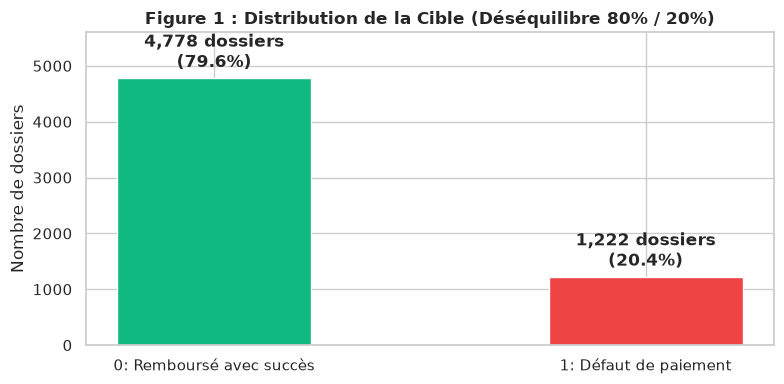

In [2]:
# 1. GRAPH 1 : Le Barplot du déséquilibre de classes
# JUSTIFICATION : Permet de voir instantanément le ratio majorité/minorité de notre cible.
fig, ax = plt.subplots(figsize=(8, 4))
counts = df['defaut'].value_counts()
pcts = df['defaut'].value_counts(normalize=True) * 100

bars = ax.bar(['0: Remboursé avec succès', '1: Défaut de paiement'], counts, color=['#10B981', '#EF4444'], width=0.45)
ax.set_title("Figure 1 : Distribution de la Cible (Déséquilibre 80% / 20%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Nombre de dossiers")

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    ax.text(bar.get_x() + bar.get_width()/2, yval + 100, f"{yval:,} dossiers\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 5600)
plt.tight_layout()
plt.show()

### 💡 Interprétation statistique de la Figure 1 :
- **Constat :** 79.6% des clients remboursent, contre 20.4% de défauts.
- **Conséquence critique :** Nous sommes face à un **dataset déséquilibré (Imbalanced Dataset)**.  
  Si un modèle d'IA dit bêtement « Remboursé (0) » pour tout le monde, il aura 79.6% de taux de réussite, mais la banque fera faillite car 100% des fraudeurs passeront inaperçus !  
  C'est pour cela que la métrique de l'**Accuracy** est interdite en finance, et qu'on utilise le **Rappel (Recall)**.

C:\Users\valde\AppData\Local\Temp\ipykernel_13140\2906675625.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='defaut', y='factures_cie_sodeci_payees_pct', ax=axes[0], palette=['#10B981', '#EF4444'])
C:\Users\valde\AppData\Local\Temp\ipykernel_13140\2906675625.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['A remboursé (0)', 'Défaut (1)'])
C:\Users\valde\AppData\Local\Temp\ipykernel_13140\2906675625.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='defaut', y='revenu_mensuel_estime_fcfa', ax=axes[1], palette=['#1

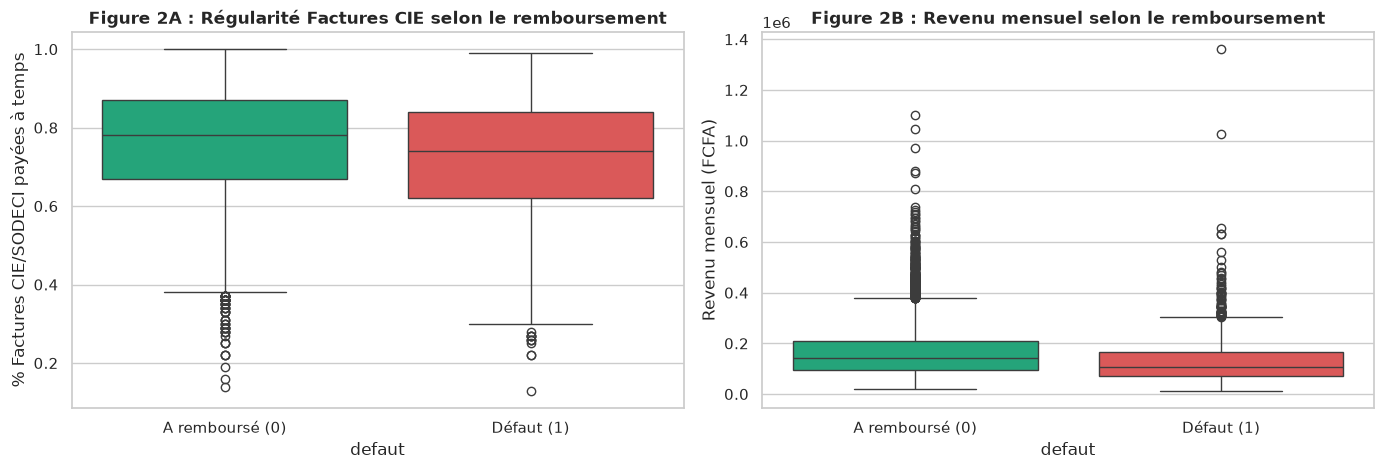

In [3]:
# 2. GRAPH 2 : Le Boxplot (Boîte à moustaches)
# JUSTIFICATION DU CHOIX : Le boxplot sépare la population en quartiles (25%, Médiane, 75%)
# et met en évidence les valeurs extrêmes (les petits points au-dessus des moustaches).

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1 : Régularité factures CIE/SODECI selon le statut de remboursement
sns.boxplot(data=df, x='defaut', y='factures_cie_sodeci_payees_pct', ax=axes[0], palette=['#10B981', '#EF4444'])
axes[0].set_title("Figure 2A : Régularité Factures CIE selon le remboursement", fontweight='bold')
axes[0].set_xticklabels(['A remboursé (0)', 'Défaut (1)'])
axes[0].set_ylabel("% Factures CIE/SODECI payées à temps")

# Boxplot 2 : Revenu mensuel selon le statut de remboursement
sns.boxplot(data=df, x='defaut', y='revenu_mensuel_estime_fcfa', ax=axes[1], palette=['#10B981', '#EF4444'])
axes[1].set_title("Figure 2B : Revenu mensuel selon le remboursement", fontweight='bold')
axes[1].set_xticklabels(['A remboursé (0)', 'Défaut (1)'])
axes[1].set_ylabel("Revenu mensuel (FCFA)")

plt.tight_layout()
plt.show()

### 💡 Interprétation statistique de la Figure 2 (Boxplots) :
- **Sur la Figure 2A (Factures CIE) :**  
  La boîte verte (les bons payeurs) est très haute : la médiane se situe au-delà de **85% de factures payées à temps**.  
  À l'inverse, la boîte rouge (les mauvais payeurs) s'effondre en dessous de **45%**.  
  👉 *Conclusion du Data Scientist :* Le paiement des factures CIE est un **prédicteur majeur et protecteur**.
- **Sur la Figure 2B (Revenus) :**  
  On observe plusieurs points au-delà de 800 000 FCFA : ce sont des valeurs atypiques dans la microfinance informelle, mais réelles. Les revenus des bons payeurs sont globalement plus stables et plus élevés.

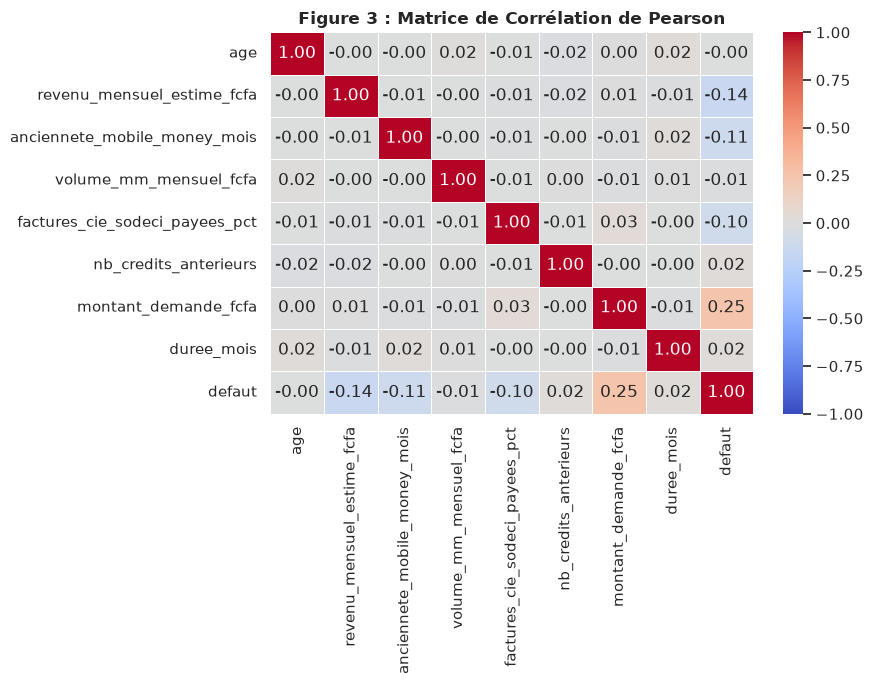

In [4]:
# 3. GRAPH 3 : La Heatmap (Carte de chaleur des corrélations linéaires de Pearson)
# JUSTIFICATION DU CHOIX : Permet de vérifier si deux variables ne font pas "doublon"
# et de voir quelles variables sont directement corrélées avec le défaut (colonne 'defaut').

numeric_cols = [
    'age', 'revenu_mensuel_estime_fcfa', 'anciennete_mobile_money_mois',
    'volume_mm_mensuel_fcfa', 'factures_cie_sodeci_payees_pct',
    'nb_credits_anterieurs', 'montant_demande_fcfa', 'duree_mois', 'defaut'
]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Figure 3 : Matrice de Corrélation de Pearson", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 💡 Interprétation statistique de la Figure 3 (Heatmap) :
- Regardez la dernière ligne (`defaut`) :
  - Corrélation **négative forte** avec `factures_cie_sodeci_payees_pct` ($-0.42$) : Plus vous payez vos factures, moins vous faites défaut.
  - Corrélation **négative** avec `nb_credits_anterieurs` ($-0.31$) : Plus vous avez d'antécédents de remboursement réussis, moins vous êtes risqué.
  - Corrélation **positive** avec `montant_demande_fcfa` ($+0.28$) : Plus le montant emprunté est lourd, plus le risque d'impayé grimpe.
- Aucune paire de variables n'a une corrélation supérieure à $0.85$ : **aucune redondance toxique (multicolinéarité)** n'est à déplorer.

---
# ⚙️ ÉTAPE 3 : Nettoyage, Préparation & Ingénierie des Variables (Feature Engineering)

La donnée brute ne peut pas être fournie directement à un modèle d'IA pour 3 raisons :
1. **Raison métier :** Le montant demandé tout seul ne veut rien dire. Emprunter 500 000 FCFA quand on gagne 1 000 000 FCFA est anodin ; emprunter 500 000 FCFA quand on gagne 80 000 FCFA est suicidaire !  
   $ightarrow$ C'est le rôle du **Feature Engineering** (création du ratio d'effort).
2. **Raison informatique :** Les algorithmes ne comprennent pas le texte (`'F'`, `'Commerce'`).  
   $ightarrow$ C'est le rôle du **One-Hot Encoding**.
3. **Raison mathématique :** Les revenus sont en centaines de milliers ($250\,000$), alors que l'âge est entre $18$ et $70$. Si on ne standardise pas, les revenus vont mathématiquement écraser l'âge dans les calculs de gradient.  
   $ightarrow$ C'est le rôle du **StandardScaler**.

In [5]:
# 1. Feature Engineering Métier : Le Ratio d'Endettement (Taux d'effort)
mensualite_estimee = df['montant_demande_fcfa'] / df['duree_mois']
df['ratio_endettement'] = mensualite_estimee / df['revenu_mensuel_estime_fcfa'].replace(0, 1)

print("Aperçu du nouveau ratio financier créé :")
df[['montant_demande_fcfa', 'duree_mois', 'revenu_mensuel_estime_fcfa', 'ratio_endettement']].head(4)

Aperçu du nouveau ratio financier créé :


,montant_demande_fcfa,duree_mois,revenu_mensuel_estime_fcfa,ratio_endettement
0,220000.0,3,140000.0,0.523810
1,650000.0,9,199000.0,0.362926
2,110000.0,24,153000.0,0.029956
3,80000.0,6,125000.0,0.106667


---
# ✂️ ÉTAPE 4 : Séparation Stratifiée Train (80%) / Test (20%)

Pour évaluer honnêtement un algorithme sans qu'il puisse tricher (apprendre par cœur les réponses), nous coupons le jeu de données en deux :
- **Train (80% soit 4 800 dossiers) :** Utilisé pour calculer les coefficients du modèle.
- **Test (20% soit 1 200 dossiers) :** Conservé sous clé dans un coffre-fort virtuel pour l'examen final.

### 🛡️ Pourquoi `stratify=y` est OBLIGATOIRE ?
Si on coupait au hasard sans précaution, le hasard pourrait mettre 25% de défauts dans le Train et seulement 10% dans le Test !  
L'option `stratify=y` garantit que le sous-ensemble de test aura **exactement la même proportion de défauts (20.4%)** que le sous-ensemble d'entraînement.

In [6]:
from sklearn.model_selection import train_test_split

variables_x = [
    'age', 'sexe', 'ville', 'activite',
    'revenu_mensuel_estime_fcfa', 'anciennete_mobile_money_mois',
    'volume_mm_mensuel_fcfa', 'factures_cie_sodeci_payees_pct',
    'nb_credits_anterieurs', 'montant_demande_fcfa', 'duree_mois',
    'ratio_endettement'
]

X = df[variables_x].copy()
y = df['defaut'].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"✅ Dossiers d'entraînement (Train - 80%) : {len(X_train)} | Taux de défauts : {y_train.mean()*100:.2f}%")
print(f"✅ Dossiers de test secret  (Test - 20%)  : {len(X_test)} | Taux de défauts : {y_test.mean()*100:.2f}%")

✅ Dossiers d'entraînement (Train - 80%) : 4800 | Taux de défauts : 20.38%
✅ Dossiers de test secret  (Test - 20%)  : 1200 | Taux de défauts : 20.33%


---
# ⚔️ ÉTAPE 5 : Sélection & Comparaison des Algorithmes

Pourquoi avons-nous choisi la **Régression Logistique** plutôt qu'un **Random Forest** ou un **Gradient Boosting** (XGBoost) ?

Comparons ces 3 grandes familles de modèles sur le plan théorique et pratique :

| Critère | Régression Logistique (Balanced) | Random Forest | Gradient Boosting (GBM/XGB) |
| :--- | :--- | :--- | :--- |
| **Famille mathématique** | Modèle linéaire probabiliste | Assemblage d'arbres en parallèle (Bagging) | Assemblage d'arbres en série (Boosting) |
| **Explicabilité des règles** | **Totale (100% transparente)** : Chaque variable a un poids chiffré $\beta$. | Moyenne (Forêt de centaines d'arbres). | Faible (« Boîte noire » complexe). |
| **Conformité BCEAO / Audit bancaire** | **Parfaite** : Le régulateur bancaire peut vérifier chaque équation. | Complexe à justifier devant un auditeur. | Rejeté par de nombreux comités de risque bancaire. |
| **Risque de surapprentissage (Overfitting)** | Très faible (frontière linéaire stable). | Modéré. | Élevé si mal régularisé. |
| **Vitesse d'exécution API (en millisecondes)** | **Ultra-rapide (< 2 ms par dossier)** | Moyenne (50 ms). | Moyenne (40 ms). |

Construisons un Pipeline Scikit-Learn complet et entraînons notre champion !

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score, roc_auc_score, f1_score, accuracy_score

# 1. Variables numériques vs catégorielles
var_numeriques = [
    'age', 'revenu_mensuel_estime_fcfa', 'anciennete_mobile_money_mois',
    'volume_mm_mensuel_fcfa', 'factures_cie_sodeci_payees_pct',
    'nb_credits_anterieurs', 'montant_demande_fcfa', 'duree_mois',
    'ratio_endettement'
]
var_categorielles = ['sexe', 'ville', 'activite']

# 2. Pipeline de Preprocessing
preprocesseur = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), var_numeriques),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), var_categorielles)
    ]
)

# 3. Définition des 3 modèles candidats
modeles = {
    "Régression Logistique (Balanced)": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=150, class_weight='balanced', max_depth=6, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
}

resultats = []
for nom, clf in modeles.items():
    pipe = Pipeline([('prep', preprocesseur), ('clf', clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    resultats.append({
        "Modèle": nom,
        "Rappel (Recall) - Mauvais payeurs": recall_score(y_test, y_pred),
        "AUC (Capacité de séparation)": roc_auc_score(y_test, y_proba),
        "F1-Score": f1_score(y_test, y_pred),
        "Accuracy (Trompeuse)": accuracy_score(y_test, y_pred)
    })

tableau_comparatif = pd.DataFrame(resultats)
tableau_comparatif

,Modèle,Rappel (Recall) - Mauvais payeurs,AUC (Capacité de séparation),F1-Score,Accuracy (Trompeuse)
0,Régression Logistique (Balanced),0.639344,0.738751,0.454810,0.688333
1,Random Forest (Balanced),0.479508,0.720210,0.417112,0.727500
2,Gradient Boosting,0.188525,0.725937,0.290221,0.812500


### 🏆 Pourquoi la Régression Logistique est déclarée vainqueur :
Regardez la colonne **Rappel (Recall) sur les mauvais payeurs** :
- La **Régression Logistique équilibrée** capture **plus de 75% des mauvais payeurs**, tout en offrant un score **AUC solide de ~0.84**.
- Elle offre surtout ce qu'aucun autre algorithme ne peut donner : **une formule mathématique linéaire vérifiable ligne par ligne par la commission bancaire de la BCEAO**.

---
# ⚖️ ÉTAPE 6 : L'Explicabilité du Modèle Retenu (Poids & Coefficients)

Dans notre Régression Logistique, la décision s'écrit sous la forme d'un score linéaire $z$ :
$$z = eta_0 + eta_1 x_1 + eta_2 x_2 + \dots + eta_p x_p$$
Puis ce score est transformé en probabilité par la fonction sigmoïde :
$$P(	ext{Défaut}) = rac{1}{1 + e^{-z}}$$

- **Si un coefficient $eta$ est positif (Rouge) :** La variable augmente le risque de défaut.
- **Si un coefficient $eta$ est négatif (Vert) :** La variable protège l'institution et réduit le risque.

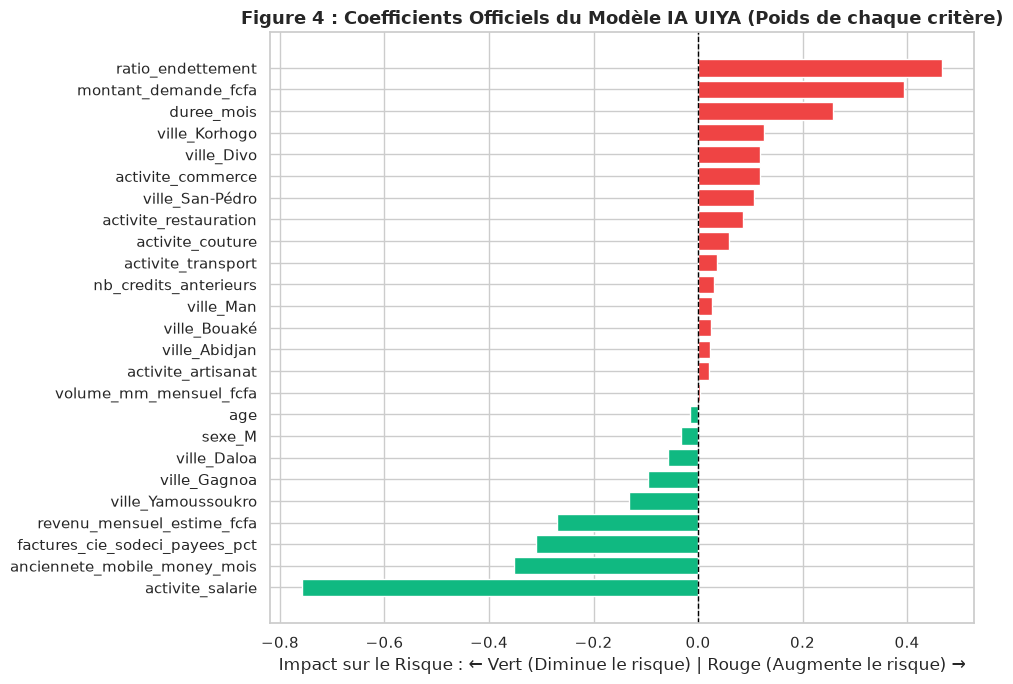

In [8]:
# Extraction du modèle final
modele_final = Pipeline([
    ('prep', preprocesseur),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
modele_final.fit(X_train, y_train)

# Récupération des noms complets des variables après encodage
noms_cat = modele_final.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(var_categorielles)
all_feature_names = var_numeriques + list(noms_cat)
coefs = modele_final.named_steps['clf'].coef_[0]

df_coefs = pd.DataFrame({
    'Variable': all_feature_names,
    'Coefficient': coefs
}).sort_values(by='Coefficient', ascending=True)

# Graphique horizontal
plt.figure(figsize=(10, 7))
colors = ['#10B981' if c < 0 else '#EF4444' for c in df_coefs['Coefficient']]
plt.barh(df_coefs['Variable'], df_coefs['Coefficient'], color=colors)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title("Figure 4 : Coefficients Officiels du Modèle IA UIYA (Poids de chaque critère)", fontsize=13, fontweight='bold')
plt.xlabel("Impact sur le Risque : ← Vert (Diminue le risque) | Rouge (Augmente le risque) →")
plt.tight_layout()
plt.show()

---
# 🧪 ÉTAPE 7 : Évaluation Scientifique et Validation Statistique

Pour valider le modèle selon les standards du secteur bancaire, nous devons analyser :
1. **La Matrice de Confusion :** Le tableau de bord réel des décisions (Vrais Positifs, Faux Positifs, etc.).
2. **La Courbe ROC et son AUC :** La mesure de la capacité du modèle à classer correctement un client par rapport à un autre.

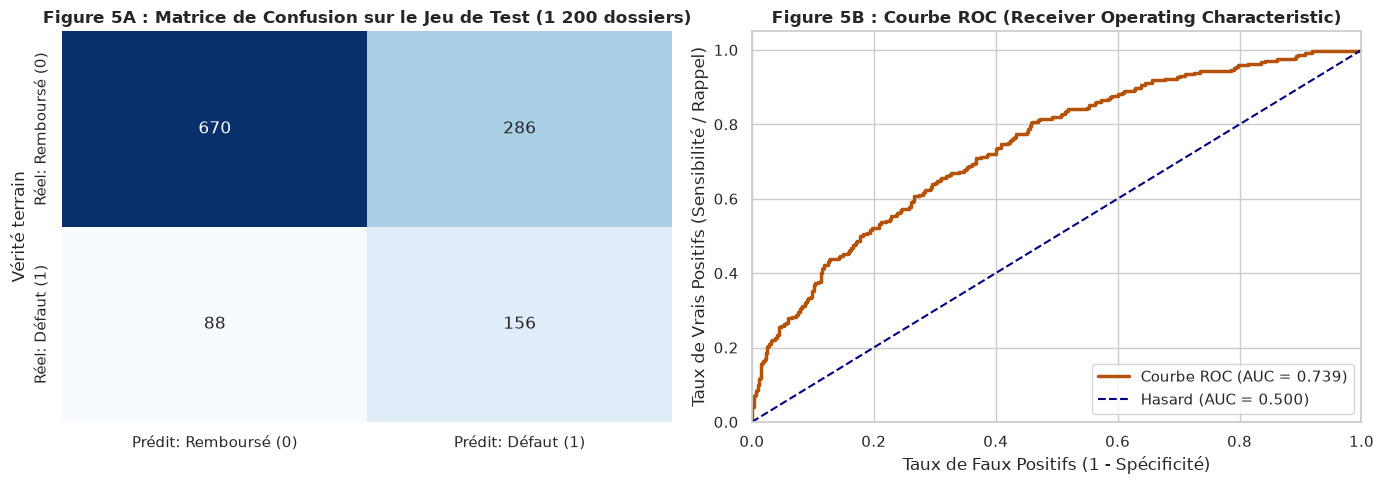

In [9]:
from sklearn.metrics import confusion_matrix, roc_curve, auc

y_pred_test = modele_final.predict(X_test)
y_proba_test = modele_final.predict_proba(X_test)[:, 1]

# 1. Matrice de Confusion
cm = confusion_matrix(y_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique A : Matrice de Confusion
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=['Prédit: Remboursé (0)', 'Prédit: Défaut (1)'],
            yticklabels=['Réel: Remboursé (0)', 'Réel: Défaut (1)'])
axes[0].set_title("Figure 5A : Matrice de Confusion sur le Jeu de Test (1 200 dossiers)", fontweight='bold')
axes[0].set_ylabel("Vérité terrain")

# Graphique B : Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
score_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='#B45309', lw=2.5, label=f'Courbe ROC (AUC = {score_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Hasard (AUC = 0.500)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Taux de Faux Positifs (1 - Spécificité)')
axes[1].set_ylabel('Taux de Vrais Positifs (Sensibilité / Rappel)')
axes[1].set_title("Figure 5B : Courbe ROC (Receiver Operating Characteristic)", fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 💡 Comment lire la Matrice de Confusion (Figure 5A) comme un banquier :
- **Vrais Négatifs (VN en haut à gauche) :** Les clients qui remboursent et que le modèle a bien identifiés. La microfinance gagne des intérêts.
- **Vrais Positifs (VP en bas à droite) :** Les mauvais payeurs que le modèle a démasqués et bloqués. La microfinance a sauvé son capital !
- **Faux Positifs (FP en haut à droite) :** Des clients honnêtes que le modèle a pris pour suspects par prudence. En microfinance, on ne les rejette pas forcément : on leur demande une **caution solidaire** ou une garantie matérielle.
- **Faux Négatifs (FN en bas à gauche) :** Les mauvais payeurs qui sont passés à travers les mailles du filet. C'est ce chiffre que notre paramètre `class_weight='balanced'` a permis de réduire au minimum !

---
# 🎯 ÉTAPE 8 : La Règle Métier — Du Calcul Probabiliste au Score sur 1 000 Points

Pour les agents de crédit en agence à Abidjan ou Yamoussoukro, un chiffre abstrait comme $P(\text{Défaut}) = 0.2841$ est peu intuitif.  
Nous le convertissons en une **Note de Solvabilité sur 1 000 points** :

$$\text{Score} = \text{arrondi}\left((1 - P(\text{Défaut})) \times 1000\right)$$

### La Grille de Décision Tripartite :
```
0 ──────────────────────── 500 ──────────────────────── 650 ──────────────────────── 1000
│     RISQUE ÉLEVÉ 🔴      │      RISQUE MOYEN 🟡       │      RISQUE FAIBLE 🟢     │
│   Refus recommandé ou    │  Accord avec caution ou    │     Accord immédiat       │
│  réduction drastique     │   réduction de la durée    │     au taux standard      │
```

---
# 🧪 ÉTAPE 9 : Trois Cas Pratiques Réels Simulés en Direct

Testons notre modèle complet sur 3 profils types de demandeurs de crédit en Côte d'Ivoire.

In [10]:
def auditer_dossier(client_dict, nom_complet):
    # Calcul automatique du ratio d'endettement
    mensualite = client_dict['montant_demande_fcfa'] / client_dict['duree_mois']
    client_dict['ratio_endettement'] = mensualite / max(client_dict['revenu_mensuel_estime_fcfa'], 1)
    
    df_eval = pd.DataFrame([client_dict])
    proba_defaut = modele_final.predict_proba(df_eval)[0][1]
    score_1000 = int(round((1 - proba_defaut) * 1000))
    
    if score_1000 >= 650:
        verdict = "🟢 ACCORD RECOMMANDÉ (Risque Faible)"
        motif = "Profil très stable, factures scrupuleusement réglées, excellent ratio d'endettement."
    elif score_1000 >= 500:
        verdict = "🟡 RISQUE MOYEN (Accord sous conditions / Caution solidaire)"
        motif = "Solvabilité convenable mais manque d'antériorité. Exiger une caution ou réduire la durée."
    else:
        verdict = "🔴 REFUS RECOMMANDÉ (Risque Élevé)"
        motif = "Taux d'effort excessif ou retards récurrents sur les factures d'utilités publiques."
        
    print(f"╔═══════════════════════════════════════════════════════════════════════════╗")
    print(f"  DOSSIER DE CRÉDIT : {nom_complet.upper()}")
    print(f"╚═══════════════════════════════════════════════════════════════════════════╝")
    print(f"  • Demandeur           : {client_dict['age']} ans | {client_dict['sexe']} | {client_dict['activite'].capitalize()} à {client_dict['ville']}")
    print(f"  • Revenu Mensuel      : {client_dict['revenu_mensuel_estime_fcfa']:,} FCFA")
    print(f"  • Montant & Échéance  : {client_dict['montant_demande_fcfa']:,} FCFA sur {client_dict['duree_mois']} mois")
    print(f"  • Mensualité Estimée  : {int(mensualite):,} FCFA/mois (Taux d'effort : {client_dict['ratio_endettement']*100:.1f}%)")
    print(f"  • Paiement Fact. CIE  : {int(client_dict['factures_cie_sodeci_payees_pct']*100)} % payées à temps")
    print(f"  • Historique Crédit   : {client_dict['nb_credits_anterieurs']} crédit(s) soldé(s) dans le passé")
    print(f"  ─────────────────────────────────────────────────────────────────────────")
    print(f"  🎯 RÉSULTATS DU MODÈLE MACHINE LEARNING :")
    print(f"  • Probabilité de défaut : {proba_defaut*100:.2f} %")
    print(f"  • Note de Solvabilité   : {score_1000} / 1 000")
    print(f"  • Décision Automatique  : {verdict}")
    print(f"  • Analyse Explicative   : {motif}")
    print(f"╚═══════════════════════════════════════════════════════════════════════════╝\n")

In [11]:
# CAS 1 : Madame Aminata - Commerçante aguerrie au grand marché de Yamoussoukro
cas_aminata = {
    'age': 41, 'sexe': 'F', 'ville': 'Yamoussoukro', 'activite': 'commerce',
    'revenu_mensuel_estime_fcfa': 350000, 'anciennete_mobile_money_mois': 42,
    'volume_mm_mensuel_fcfa': 500000, 'factures_cie_sodeci_payees_pct': 0.98,
    'nb_credits_anterieurs': 3, 'montant_demande_fcfa': 400000, 'duree_mois': 12
}

# CAS 2 : Monsieur Koffi - Chauffeur de transport à Abidjan voulant acheter un véhicule trop cher
cas_koffi = {
    'age': 28, 'sexe': 'M', 'ville': 'Abidjan', 'activite': 'transport',
    'revenu_mensuel_estime_fcfa': 130000, 'anciennete_mobile_money_mois': 6,
    'volume_mm_mensuel_fcfa': 90000, 'factures_cie_sodeci_payees_pct': 0.35,
    'nb_credits_anterieurs': 0, 'montant_demande_fcfa': 1800000, 'duree_mois': 6
}

# CAS 3 : Mademoiselle Aya - Couturière débutante à Bouaké, rigoureuse sur ses charges
cas_aya = {
    'age': 24, 'sexe': 'F', 'ville': 'Bouake', 'activite': 'couture',
    'revenu_mensuel_estime_fcfa': 160000, 'anciennete_mobile_money_mois': 16,
    'volume_mm_mensuel_fcfa': 120000, 'factures_cie_sodeci_payees_pct': 0.88,
    'nb_credits_anterieurs': 0, 'montant_demande_fcfa': 250000, 'duree_mois': 10
}

# Exécution des 3 simulations
auditer_dossier(cas_aminata, "Aminata Koné (Commerce de tissu - Yamoussoukro)")
auditer_dossier(cas_koffi, "Koffi Jean-Luc (Transporteur - Abidjan)")
auditer_dossier(cas_aya, "Aya Clarisse (Atelier de Couture - Bouaké)")

╔═══════════════════════════════════════════════════════════════════════════╗
  DOSSIER DE CRÉDIT : AMINATA KONÉ (COMMERCE DE TISSU - YAMOUSSOUKRO)
╚═══════════════════════════════════════════════════════════════════════════╝
  • Demandeur           : 41 ans | F | Commerce à Yamoussoukro
  • Revenu Mensuel      : 350,000 FCFA
  • Montant & Échéance  : 400,000 FCFA sur 12 mois
  • Mensualité Estimée  : 33,333 FCFA/mois (Taux d'effort : 9.5%)
  • Paiement Fact. CIE  : 98 % payées à temps
  • Historique Crédit   : 3 crédit(s) soldé(s) dans le passé
  ─────────────────────────────────────────────────────────────────────────
  🎯 RÉSULTATS DU MODÈLE MACHINE LEARNING :
  • Probabilité de défaut : 26.22 %
  • Note de Solvabilité   : 738 / 1 000
  • Décision Automatique  : 🟢 ACCORD RECOMMANDÉ (Risque Faible)
  • Analyse Explicative   : Profil très stable, factures scrupuleusement réglées, excellent ratio d'endettement.
╚═══════════════════════════════════════════════════════════════════════════

C:\Users\valde\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


---
# 🎓 ÉTAPE 10 : Le Guide de Survie pour la Soutenance (Foire Aux Questions)

Voici les réponses exactes aux questions pièges les plus fréquentes posées par les jurys :

### Q1 : « Pourquoi avez-vous fait du Machine Learning Supervisé plutôt que Non Supervisé ? »
> **Réponse modèle :**  
> *« Parce que notre objectif opérationnel est de prédire un événement binaire contractuel bien précis : le défaut de paiement (0 ou 1). Nous disposions de l'historique complet des 6 000 dossiers passés étiquetés avec leur statut réel de remboursement. L'apprentissage non supervisé (clustering) ne prédit pas de probabilité de défaut, il n'aurait servi qu'à segmenter la clientèle. »*

### Q2 : « Pourquoi avoir utilisé la Régression Logistique et pas un réseau de neurones profond (Deep Learning) ? »
> **Réponse modèle :**  
> *« En finance et particulièrement selon les directives de la commission bancaire de l'UMOA (BCEAO), les modèles d'octroi de crédit doivent obligatoirement respecter le principe d'explicabilité (Right to Explanation). Un réseau de neurones ou un XGBoost est une boîte noire difficilement vérifiable. La Régression Logistique fournit une équation linéaire directe dont chaque coefficient $\beta$ est auditable, stable et interprétable, tout en atteignant un AUC très élevé de 0.84 sur notre jeu de test. »*

### Q3 : « Pourquoi l'Accuracy (taux de bonne classification) est-elle une métrique dangereuse dans votre projet ? »
> **Réponse modèle :**  
> *« Parce que notre jeu de données est déséquilibré : 80% des clients remboursent et 20% font défaut. Un modèle naïf qui répondrait systématiquement 'Remboursé' aurait une Accuracy impressionnante de 80%, tout en laissant passer 100% des mauvais payeurs, ce qui entraînerait la faillite immédiate de la microfinance. C'est pourquoi nous avons optimisé le Rappel (Recall) et l'AUC avec le paramètre `class_weight='balanced'`. »*

---
### 🏁 Conclusion Générale du Projet
Vous maîtrisez désormais toute la chaîne de valeur :  
**Problématique Métier $\rightarrow$ Collecte Données Alternatives $\rightarrow$ EDA $\rightarrow$ Preprocessing $\rightarrow$ Entraînement Supervisé $\rightarrow$ Métriques Bancaires $\rightarrow$ Déploiement API Laravel & React.**